<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">Procesamiento de Lenguaje Natural · Proyecto Final</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">Preprocesamiento y Representación TF-IDF del Conjunto de Datos POLAR (SemEval-2026 Task 9)</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Pérez Martínez Ángel Noel, Zamora Antiga Ángel Javier</div><img src="https://raw.githubusercontent.com/makore-0612/vibe-rhythming/refs/heads/main/assets/logoinst.png" width="200"/></div>

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Objetivo</span></div>

En este notebook se limpian los textos de los 22 idiomas con un mismo procedimiento y se construye su representación vectorial con TF-IDF sobre n-gramas de caracteres. Esta representación es la entrada de los clasificadores de las siguientes etapas.

Se decidió no lematizar, ya que las herramientas disponibles (NLTK, spaCy, Stanza) no cubren todos los idiomas del conjunto y se terminaría con un preprocesamiento distinto para cada uno. Los n-gramas de caracteres resuelven buena parte del mismo problema sin depender del idioma, puesto que las palabras con la misma raíz comparten la mayoría de sus n-gramas. Además, no hace falta separar palabras en chino, jemer o birmano, y toleran mejor las faltas de ortografía.

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Preparación de entorno</span></div>

In [1]:
# Manejo de datos
import os
import re
import glob
import unicodedata
import joblib
import numpy as np
import pandas as pd
from scipy import sparse

# Procesamiento de texto
import regex
import emoji
from sklearn.feature_extraction.text import TfidfVectorizer

# Visualización
import matplotlib.pyplot as plt

# Reproducibilidad
random_state = 42

# Rutas y grupos de etiquetas por subtarea
ruta_datos = 'data'
ruta_procesado = os.path.join(ruta_datos, 'procesado')
ruta_tfidf = os.path.join(ruta_datos, 'tfidf')
tipos = ['political', 'racial/ethnic', 'religious', 'gender/sexual', 'other']
manifestaciones = ['stereotype', 'vilification', 'dehumanization', 'extreme_language', 'lack_of_empathy', 'invalidation']
etiquetas = ['polarization'] + tipos + manifestaciones

pd.set_option('display.max_colwidth', 200)

Se importan las librerías y se definen las rutas de entrada y salida, junto con las listas de etiquetas de cada subtarea. Para las expresiones regulares se importa el módulo `regex` además de `re`, y la siguiente celda muestra por qué.

In [2]:
# re vs regex con escrituras que usan marcas combinantes
ejemplo = 'हिन्दी తెలుగు ខ្មែរ မြန်မာ'
print(f"Original: {ejemplo}")
print(f"re:       {re.sub(r'[^\w\s]', '', ejemplo)}")
print(f"regex:    {regex.sub(r'[^\p{L}\p{M}\p{N}\s]', '', ejemplo)}")

Original: हिन्दी తెలుగు ខ្មែរ မြန်မာ
re:       हनद తలగ ខមរ မနမ
regex:    हिन्दी తెలుగు ខ្មែរ မြန်မာ


La celda aplica la misma limpieza con `re` y con `regex` a palabras en hindi, telugu, jemer y birmano. En `re`, la clase `\w` no incluye las marcas combinantes (categorías Unicode `Mn` y `Mc`), que en escrituras como el devanagari, el telugu, el jemer o el birmano representan las vocales. Por eso, al eliminar todo lo que no sea `\w`, `re` destruye las palabras, como se ve en la salida. En cambio, `regex` permite usar las categorías Unicode de forma explícita (`\p{L}` para letras, `\p{M}` para marcas y `\p{N}` para números) y deja el texto intacto.

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Carga de datos</span></div>

In [3]:
def cargar_particion(particion):
    """
    Función que carga y concatena los archivos de todos los idiomas de una partición

    inputs:
    --------
        particion (str): Nombre de la carpeta ('train' o 'test')

    outputs:
    --------
        pandas.DataFrame: Registros de todos los idiomas con una columna adicional 'idioma'
    """
    archivos = sorted(glob.glob(os.path.join(ruta_datos, particion, '*.csv')))
    dfs = [pd.read_csv(f).assign(idioma = os.path.basename(f)[:3]) for f in archivos]
    return pd.concat(dfs, ignore_index = True)

train = cargar_particion('train')
test = cargar_particion('test')

# El canary no aporta información, pero se conserva para volver a escribirlo en el test procesado
canary = test['canary'].unique()
assert len(canary) == 1
canary = canary[0]
test = test.drop(columns = ['canary'])
idiomas = sorted(train['idioma'].unique())

print(f'Tamaño de train: {train.shape}')
print(f'Tamaño de test: {test.shape}')

Tamaño de train: (73681, 15)
Tamaño de test: (33288, 15)


Se cargan las dos particiones con la misma función del análisis exploratorio. La columna `canary` se quita de `test`, pero su valor se guarda para volver a escribirlo en el archivo de prueba procesado al final del notebook.

In [4]:
# Textos de train que también están en test
fuga = train['text'].isin(test['text'])
display(train.loc[fuga, ['id', 'idioma', 'text', 'polarization']]
        .merge(test[['id', 'text', 'polarization']], on = 'text', suffixes = ('_train', '_test')))
print(f'Textos de train idénticos a uno de test: {fuga.sum()}')

,id_train,idioma,text,polarization_train,id_test,polarization_test
0,pan_7b397b165ec40faf3f6c7c32a9e6ae05,pan,دوست مزاری پر اصولاً یہاں توہین عدالت اور آئین کی خلاف ورزی کی شقیں بھی لگ سکتی. لیکن ایتھے کیہڑے اصول,0,urd_7b397b165ec40faf3f6c7c32a9e6ae05,1
1,tur_63390f8d0fbf81e2f2a406d41fa6f1ef,tur,"@USER @USER Esasında sizin burada Ak Partiyi itham ve iftiralarınıza suç duyurusu şart ,5 dakikalığına kiraya verdiğiniz aklınızı geri alabilseniz tüm çıplaklığıyla gerçekleri hakikatları göreceks...",1,tur_63390f8d0fbf81e2f2a406d41fa6f1ef,1
2,tur_7f30cd79b49984d0648dd4e717bba7bf,tur,@USER Avukatlığını yaptığın Rusya orada ABD hesabına çalışıyor. Sivil halka yöneklik pis işi kontrat üzerine yapıyor. Gerçi o kadar İslamcı teröristi oraya sokan da ABD ve onun mafya tetikçisi Rus...,1,tur_7f30cd79b49984d0648dd4e717bba7bf,1
3,tur_9d62f60bd9122f26bfa5204f50cfb037,tur,@USER @USER Yorumlara bakinca Amerikalıların ne kadar cahil bir toplum olduğu çok net görünüyor.,0,tur_9d62f60bd9122f26bfa5204f50cfb037,1


Textos de train idénticos a uno de test: 4


En el análisis exploratorio se encontraron 4 textos de prueba idénticos a textos de entrenamiento, y esta celda los muestra junto con su registro equivalente en `test`. Los tres de turco tienen el mismo `id` en ambas particiones, así que se trata del mismo registro repetido. El cuarto es un texto en panyabí escrito en alfabeto shahmukhi (derivado del árabe, como el urdu), que aparece como `pan` en `train` y como `urd` en `test` con el mismo hash en el `id`. En dos de los cuatro casos la etiqueta de polarización no coincide entre particiones, lo que muestra que la anotación tiene algo de ruido.

Por ahora solo se revisan. Se eliminan de `train` después de la limpieza, junto con los textos que solo se distinguen por detalles de formato (menciones, puntuación o mayúsculas) y que una comparación exacta del texto crudo no detecta.

In [5]:
# Se unen ambas particiones para aplicar cada paso de limpieza una sola vez
datos = pd.concat([train.assign(particion = 'train'), test.assign(particion = 'test')], ignore_index = True)
datos['texto'] = datos['text']
print(f'Registros totales: {len(datos)}')

Registros totales: 106969


Se juntan ambas particiones en un solo `DataFrame`, con una columna `particion` que indica de dónde viene cada registro, para aplicar cada paso de limpieza una sola vez. El texto original se conserva en `text` y la versión limpia se va construyendo en `texto`. Procesar `train` y `test` juntos no introduce fuga, debido a que cada paso de limpieza es una regla fija que no aprende nada de los datos.

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Limpieza de texto</span></div>

In [6]:
def mostrar_cambios(antes, despues, n = 4, largo_max = 160):
    """
    Función que reporta cuántos textos modificó un paso de limpieza y muestra algunos ejemplos

    inputs:
    --------
        antes (pandas.Series): Textos antes de aplicar el paso
        despues (pandas.Series): Textos después de aplicar el paso
        n (int): Cantidad de ejemplos a mostrar
        largo_max (int): Longitud máxima de los ejemplos, para que el cambio sea visible

    outputs:
    --------
        None
    """
    cambio = antes != despues
    print(f'Textos modificados: {cambio.sum()} ({round(100 * cambio.mean(), 2)}%)')
    candidatos = cambio & (antes.str.len() <= largo_max)
    if candidatos.sum() >= n:
        muestra = antes[candidatos].sample(n, random_state = random_state).index
        display(pd.DataFrame({'idioma': datos.loc[muestra, 'idioma'],
                              'antes': antes[muestra],
                              'después': despues[muestra]}))

La función `mostrar_cambios` compara los textos antes y después de un paso de limpieza, reporta cuántos cambiaron y muestra algunos ejemplos cortos para que el cambio sea visible. Se usa después de cada paso para comprobar que hace lo que se espera.

La limpieza se aplica en el siguiente orden, ya que algunos pasos dependen de los anteriores.

1. Normalización Unicode
2. Unificación de marcadores de usuario y enlaces
3. Reducción de caracteres repetidos
4. Conversión de emojis a texto
5. Eliminación del símbolo `#` de los hashtags
6. Puntuación, donde los signos de fin de oración se convierten en punto y lo demás se elimina
7. Conversión a minúsculas
8. Espacios

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">1. Normalización Unicode</span></div>

In [7]:
antes = datos['texto'].copy()
datos['texto'] = datos['texto'].map(lambda t: unicodedata.normalize('NFKC', t))
mostrar_cambios(antes, datos['texto'])

Textos modificados: 11491 (10.74%)


,idioma,antes,después
73185,zho,对对对，台湾人对我们的恨意是远大于外国人的，外国人哪怕是歧视也只是讨厌的程度，台湾人是真的仇视,"对对对,台湾人对我们的恨意是远大于外国人的,外国人哪怕是歧视也只是讨厌的程度,台湾人是真的仇视"
90093,mya,မ ဆိုး ပါ ဘူး ဘာ ပဲ ပြောပြော အနုပညာ သဘော ပဲ ကြည့် ကြ ပါ ဗျာ တဏှာ ဘက် က မ ကြည့် ကြ နဲ့ ပေါ့,မ ဆိုး ပါ ဘူး ဘာ ပဲ ပြောပြော အနုပညာ သဘော ပဲ ကြည့် ကြ ပါ ဗျာ တဏှာ ဘက် က မ ကြည့် ကြ နဲ့ ပေါ့
6920,ben,সময় টিভির অসময় অচিরে আসবে ছোট্ট খাটো গুলো খেয়ে লাভ নেই বেচে বেচে অবৈধ সরকারের ডিজিটাল কুত্তা লীগ পুলিশ খেলে দেশের জনগণ একটু শান্তি তে থাকতে পারবে,সময় টিভির অসময় অচিরে আসবে ছোট্ট খাটো গুলো খেয়ে লাভ নেই বেচে বেচে অবৈধ সরকারের ডিজিটাল কুত্তা লীগ পুলিশ খেলে দেশের জনগণ একটু শান্তি তে থাকতে পারবে
72298,zho,那个 山东也是全国 排名靠前的省，不过全国哪里都有经济条件没那么好的人吧,"那个 山东也是全国 排名靠前的省,不过全国哪里都有经济条件没那么好的人吧"


Un mismo carácter puede codificarse de varias formas, por ejemplo con un solo código o como letra base más marca combinante, en versión de ancho completo (común en chino) o como forma de presentación (común en árabe). La normalización **NFKC** lleva todas estas variantes a una sola forma canónica, de modo que `ＡＢＣ` pasa a `ABC`, `？` a `?` y `…` a `...`, lo que también simplifica el paso de puntuación.

Se modificó cerca del 11% de los textos. En la mayoría el cambio no se nota a simple vista porque solo cambia la codificación interna, como en bengalí y birmano, donde algunas letras compuestas se representaban con dos códigos. En chino sí se nota, ya que las comas de ancho completo `，` pasan a `,` y así el paso de puntuación las reconoce como cualquier otra coma.

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">2. Marcadores de usuario y enlaces</span></div>

In [8]:
# Variantes de marcadores presentes en el corpus
patron_marcadores = r'@USER\b|\[pseudonym\]|@URL\b|##url\b|\[URL\]|https?://\S+|<nl>'
variantes = datos['texto'].str.findall(patron_marcadores).explode().dropna()
print(variantes.str.replace(r'https?://\S+', 'http(s)://...', regex = True).value_counts())

texto
@USER          13797
@URL            2318
##url           1551
[URL]            184
[pseudonym]       49
<nl>              28
Name: count, dtype: int64


Antes de reemplazar nada se cuentan las variantes de marcadores que hay en el corpus. El conjunto ya viene anonimizado, pero no de la misma forma en todos los idiomas, puesto que las menciones aparecen como `@USER` o `[pseudonym]` y los enlaces como `@URL`, `##url`, `[URL]` o direcciones completas. La variante más común es `@USER`, con casi 14 mil apariciones.

In [9]:
antes = datos['texto'].copy()
datos['texto'] = (datos['texto']
                  .str.replace(r'@USER\b|\[pseudonym\]', ' xxuser ', regex = True)
                  .str.replace(r'@URL\b|##url\b|\[URL\]|https?://\S+', ' xxurl ', regex = True)
                  .str.replace('<nl>', ' ', regex = False))
mostrar_cambios(antes, datos['texto'])

Textos modificados: 13590 (12.7%)


,idioma,antes,después
47253,pol,pozwolę sobie zacytować: \n @URL,pozwolę sobie zacytować: \n xxurl
83228,hau,kaifa dama jakine shege jahili 😮 ##url,kaifa dama jakine shege jahili 😮 xxurl
29310,ita,"@USER Girare per Roma sta diventando deprimente, barboni, nomadi ed immigrati ovunque, la città a pezzi. @USER","xxuser Girare per Roma sta diventando deprimente, barboni, nomadi ed immigrati ovunque, la città a pezzi. xxuser"
21252,hau,@USER kai ai dolo ne ai! baza ka taba fahimta,xxuser kai ai dolo ne ai! baza ka taba fahimta


Las variantes se unifican en dos tokens, `xxuser` y `xxurl`, que no existen en ningún idioma y que no se confunden con las palabras *user* o *url* al pasar a minúsculas. La etiqueta `<nl>` marca saltos de línea, así que se sustituye por un espacio. Este paso modificó el 12.7% de los textos.

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">3. Caracteres repetidos</span></div>

In [10]:
antes = datos['texto'].copy()
datos['texto'] = datos['texto'].map(lambda t: regex.sub(r'([^\d\s])\1{2,}', r'\1\1', t))
mostrar_cambios(antes, datos['texto'])

Textos modificados: 9733 (9.1%)


,idioma,antes,después
6005,arb,بالنسبة الخليجيين اهم من كأس العالم...... أصلا الخليجيين لا يتأهلون للمونديال,بالنسبة الخليجيين اهم من كأس العالم.. أصلا الخليجيين لا يتأهلون للمونديال
100979,swa,waaah hii ndio kenya Wakisii wote ni maumbwa,waah hii ndio kenya Wakisii wote ni maumbwa
54603,swa,Wazungu wenzangu kwenye gemu #watashaoye :) hahaha. Ningependa kuwapongeza hawa wasanii kwasababu ingawa hawapo...,Wazungu wenzangu kwenye gemu #watashaoye :) hahaha. Ningependa kuwapongeza hawa wasanii kwasababu ingawa hawapo..
69586,zho,"你不考虑检疫能力么......不是来多少人都能挨个检疫吧,黑龙江那边不就搞不定了么......","你不考虑检疫能力么..不是来多少人都能挨个检疫吧,黑龙江那边不就搞不定了么.."


Las secuencias de tres o más caracteres iguales se reducen a dos, por ejemplo `nooooo` pasa a `noo`. Se dejan dos y no uno para no perder del todo el énfasis y para no alterar palabras que llevan letras dobles legítimas. Los dígitos se excluyen para no modificar cifras como `1000`. El paso afectó al 9.1% de los textos, sobre todo en puntos suspensivos alargados y risas como `waaah`.

Este paso va antes de convertir los emojis, de modo que `😂😂😂😂` se reduce a `😂😂` mientras todavía es un solo carácter repetido.

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">4. Emojis</span></div>

In [11]:
# Emojis más frecuentes
lista_emojis = datos['texto'].map(lambda t: [e['emoji'] for e in emoji.emoji_list(t)]).explode().dropna()
print(f"Textos con al menos un emoji: {datos['texto'].map(emoji.emoji_count).gt(0).sum()}")
frecuentes = lista_emojis.value_counts().head(10)
display(pd.DataFrame({'emoji': frecuentes.index,
                      'nombre': [emoji.demojize(e, delimiters = ('', '')) for e in frecuentes.index],
                      'frecuencia': frecuentes.values}))

Textos con al menos un emoji: 6453


,emoji,nombre,frecuencia
0,😂,face_with_tears_of_joy,2404
1,🤣,rolling_on_the_floor_laughing,948
2,🙏,folded_hands,413
3,😁,beaming_face_with_smiling_eyes,377
4,😅,grinning_face_with_sweat,267
5,😭,loudly_crying_face,262
6,🤔,thinking_face,228
7,😡,enraged_face,223
8,🚩,triangular_flag,187
9,😎,smiling_face_with_sunglasses,175


Se cuentan los textos con emojis y se listan los más frecuentes. Unos 6,400 textos tienen al menos uno, y los más usados son los de risa (`face_with_tears_of_joy` y `rolling_on_the_floor_laughing`), que en este contexto muchas veces indican burla.

In [12]:
antes = datos['texto'].copy()
datos['texto'] = datos['texto'].map(lambda t: emoji.demojize(t, delimiters = (' ', ' ')))
mostrar_cambios(antes, datos['texto'])

Textos modificados: 6472 (6.05%)


,idioma,antes,después
10642,deu,"🫣 dass die Impfung nicht ganz so Nebenwirkungsfrei ist, sollte ja mittlerweile bekannt sein","face_with_peeking_eye dass die Impfung nicht ganz so Nebenwirkungsfrei ist, sollte ja mittlerweile bekannt sein"
24317,hin,"रोज रोज अस्सी पैसे बढ़ रहे हैं, ये झटका है या हलाल।😂😂 डीजल, पेट्रोल रेट।😂😂","रोज रोज अस्सी पैसे बढ़ रहे हैं, ये झटका है या हलाल। face_with_tears_of_joy face_with_tears_of_joy डीजल, पेट्रोल रेट। face_with_tears_of_joy face_with_tears_of_joy"
83544,hau,"arne, irin kai shegen nan ko😂 xxurl","arne, irin kai shegen nan ko face_with_tears_of_joy xxurl"
25475,hin,"वाह , परिवारवाद के खिलाफ भाजपा का मास्टर स्ट्रोक 😂😂 इंदिरा गांधी की छोटी बहू और मुलायम सिंह की छोटी बहू दोनों एक साथ","वाह , परिवारवाद के खिलाफ भाजपा का मास्टर स्ट्रोक face_with_tears_of_joy face_with_tears_of_joy इंदिरा गांधी की छोटी बहू और मुलायम सिंह की छोटी बहू दोनों एक साथ"


Debido a que los emojis pueden indicar burla u hostilidad, se conservan como texto con `emoji.demojize`. Cada emoji se convierte en su nombre en inglés, con guiones bajos entre palabras y un espacio a cada lado para que quede como un token independiente, de modo que `😂` pasa a ` face_with_tears_of_joy `.

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">5. Hashtags</span></div>

In [13]:
# Idiomas con más hashtags
print(datos.loc[datos['texto'].str.contains(r'#\w', regex = True), 'idioma'].value_counts().head(8))

antes = datos['texto'].copy()
datos['texto'] = datos['texto'].str.replace(r'#(?=\w)', '', regex = True)
mostrar_cambios(antes, datos['texto'])

idioma
urd    2184
hin     995
ita     851
tur     784
amh     677
rus     329
pol     311
hau     302
Name: count, dtype: int64
Textos modificados: 7902 (7.39%)


,idioma,antes,después
103786,urd,بھکاری شریف وطن بدنصیب کے 23ویں کرائم منسٹر منتخب. #امپورٹڈ_حکومٹ_نامنظور,بھکاری شریف وطن بدنصیب کے 23ویں کرائم منسٹر منتخب. امپورٹڈ_حکومٹ_نامنظور
17800,fas,فوری: حجت الاسلام والمسلمین سجاد شهرکی امام جماعت مسجد مولای متقیان(ع) #زاهدان ترور شد. #مهسا_امینی,فوری: حجت الاسلام والمسلمین سجاد شهرکی امام جماعت مسجد مولای متقیان(ع) زاهدان ترور شد. مهسا_امینی
93299,pan,سندھیلہ صاحب تسی نا تشہیر کرو کسی بچے کولوں کروا لو #یوم_نجات,سندھیلہ صاحب تسی نا تشہیر کرو کسی بچے کولوں کروا لو یوم_نجات
51669,spa,"la artista indigena australiana alma nungarrayi granites,\nseven sisters dreaming, 2016 #womensart","la artista indigena australiana alma nungarrayi granites,\nseven sisters dreaming, 2016 womensart"


La celda primero muestra los idiomas con más hashtags, donde destaca el urdu con más de 2 mil textos, y después elimina el símbolo `#` conservando la palabra. La palabra se conserva porque en varios idiomas el hashtag contiene información relevante, como `#immigrati`, `#italiani` o `#TPLF`. Los guiones bajos que unen las palabras de un hashtag, muy comunes en urdu y persa, se mantienen.

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">6. Puntuación</span></div>

In [14]:
fin_oracion = r'[\p{Sentence_Terminal}¿¡]'
otros_signos = r'[^\p{L}\p{M}\p{N}_\s\p{Sentence_Terminal}¿¡\p{Cf}]'

# Caracteres invisibles de formato
print('\t Caracteres de formato:')
print(datos['texto'].map(lambda t: regex.findall(r'\p{Cf}', t)).explode().dropna()
      .map(lambda c: unicodedata.name(c, hex(ord(c)))).value_counts().head(6))

# Signos de fin de oración más frecuentes
print('\t Signos de fin de oración:')
print(datos['texto'].map(lambda t: regex.findall(fin_oracion, t)).explode().dropna().value_counts().head(12))

# Caracteres que se eliminarán
print('\n\t Caracteres sustituidos por espacio más frecuentes:')
print(datos['texto'].map(lambda t: regex.findall(otros_signos, t)).explode().dropna().value_counts().head(12))

	 Caracteres de formato:
texto
ZERO WIDTH NON-JOINER    3268
ZERO WIDTH JOINER          64
ZERO WIDTH SPACE           49
RIGHT-TO-LEFT MARK         30
LEFT-TO-RIGHT ISOLATE      10
WORD JOINER                10
Name: count, dtype: int64
	 Signos de fin de oración:
texto
.    54199
!    12441
?    11268
។     7657
।     7574
。     3021
۔     2948
።     2304
؟     1926
။     1253
၊      636
៕      368
Name: count, dtype: int64

	 Caracteres sustituidos por espacio más frecuentes:
texto
,    38537
:     7972
"     7690
-     7466
'     5420
،     4704
)     4683
(     3984
|     1630
’     1591
/     1486
*     1092
Name: count, dtype: int64


Antes de modificar la puntuación se revisan tres cosas, los caracteres invisibles de formato, los signos de fin de oración y los caracteres que se van a sustituir por un espacio. Entre los primeros el más común es el *zero width non-joiner*. Entre los signos de fin de oración, además del punto, `!` y `?`, aparecen los de otras escrituras como `។`, `।` o `。`. Entre los caracteres que se eliminarán dominan la coma, los dos puntos, las comillas y el guion.

Solo se conservan los puntos como marca de fin de oración. Además del `.?!¿¡` del español, cada escritura tiene sus propios signos de fin de oración, como la *danda* `।` del hindi y el bengalí, `።` del amhárico, `؟` y `۔` del árabe y el urdu, `။` del birmano, `។` del jemer o `。` del chino. Todos ellos se identifican con la propiedad Unicode `Sentence_Terminal`, así que se tratan igual que `?` y `!`.

In [15]:
antes = datos['texto'].copy()

# Separadores dentro de números y apóstrofos
datos['texto'] = datos['texto'].map(lambda t: regex.sub(r'(?<=\d)[.,](?=\d)', '', t))
datos['texto'] = datos['texto'].str.replace(r"['’]", '', regex = True)

# Caracteres invisibles de formato, sin dejar espacio
datos['texto'] = datos['texto'].map(lambda t: regex.sub(r'\p{Cf}', '', t))

# Todo lo demás se sustituye por un espacio
datos['texto'] = datos['texto'].map(lambda t: regex.sub(otros_signos, ' ', t))

# Secuencias de signos de fin de oración a un solo punto
datos['texto'] = datos['texto'].map(lambda t: regex.sub(rf'[\s¿¡\p{{Sentence_Terminal}}]*{fin_oracion}[\s¿¡\p{{Sentence_Terminal}}]*', '. ', t))

mostrar_cambios(antes, datos['texto'])

Textos modificados: 67830 (63.41%)


,idioma,antes,después
64650,tur,"Ankara'da, fahiş ev kiraları ve yurt ücretlerini protesto için sokakta sabahlamak isteyen 9 öğrenci gözaltına alındı.",Ankarada fahiş ev kiraları ve yurt ücretlerini protesto için sokakta sabahlamak isteyen 9 öğrenci gözaltına alındı.
89726,khm,ពិតណាស់ កាហ្វេដែលគ្មានសារជាតិកាហ្វេអ៊ីន នៅតែមានសារជាតិកាហ្វេអ៊ីនចំនួន ៣% ។,ពិតណាស់ កាហ្វេដែលគ្មានសារជាតិកាហ្វេអ៊ីន នៅតែមានសារជាតិកាហ្វេអ៊ីនចំនួន ៣.
88953,khm,កន្លងមកខ្ញុំប្រើអណ្តូងស្នប់ដៃម្យ៉ាងនោះគុណភាពវារហ័សខូចអត់បានមួយឆ្នាំ ។,កន្លងមកខ្ញុំប្រើអណ្តូងស្នប់ដៃម្យ៉ាងនោះគុណភាពវារហ័សខូចអត់បានមួយឆ្នាំ.
78469,deu,"Die Buddhisten in Südostasien sind auch ganz groß darin Andersgläubige, vornehmlich Muslime, zu massakrieren.",Die Buddhisten in Südostasien sind auch ganz groß darin Andersgläubige vornehmlich Muslime zu massakrieren.


La limpieza de la puntuación se hace en cinco pasos.

1. Se quitan los separadores dentro de números (`3.5` pasa a `35` y `1,000` a `1000`) para que no se confundan con un punto final.
2. Se quitan los apóstrofos para no partir palabras (`don't` pasa a `dont`).
3. Se quitan los caracteres invisibles de formato (categoría Unicode `Cf`). El más común es el *zero width non-joiner*, que en persa y telugu va dentro de las palabras, así que se elimina sin dejar espacio.
4. Cualquier carácter que no sea letra, marca combinante, número, guion bajo (de los emojis), espacio o signo de fin de oración se sustituye por un espacio.
5. Cada secuencia de signos de fin de oración, aunque tenga espacios intermedios, se convierte en un solo punto, de modo que `???` y `!! ?` quedan como `.`.

Es el paso que más textos modifica (63%), lo cual tiene sentido, ya que casi cualquier texto tiene al menos una coma o algún otro signo de puntuación.

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">7. Minúsculas</span></div>

In [16]:
antes = datos['texto'].copy()

es_turco = datos['idioma'] == 'tur'
datos.loc[es_turco, 'texto'] = datos.loc[es_turco, 'texto'].str.replace('I', 'ı').str.replace('İ', 'i')
datos['texto'] = datos['texto'].str.lower()

mostrar_cambios(antes, datos['texto'])

Textos modificados: 31553 (29.5%)


,idioma,antes,después
99283,swa,WAJALUO WAMEANZA KUONA MWANGAZA KUDOS,wajaluo wameanza kuona mwangaza kudos
94412,pol,Kolejny sezonowy fan ktory oglada od 3 lat tenisa a grac nie umie.,kolejny sezonowy fan ktory oglada od 3 lat tenisa a grac nie umie.
12011,deu,Für s Klima \n\nWer s glaubt wird seelig.,für s klima \n\nwer s glaubt wird seelig.
13611,eng,Benson says clerks statewide are ready for early voting,benson says clerks statewide are ready for early voting


Se pasa todo a minúsculas para que `Odio`, `ODIO` y `odio` cuenten como la misma palabra. Esto solo afecta a las escrituras que tienen mayúsculas, como la latina y la cirílica, y por eso cambió el 29.5% de los textos. Se pierde la señal de las mayúsculas sostenidas, pero los signos de exclamación ya quedaron registrados como puntos.

El turco requiere un trato especial, puesto que su `I` mayúscula corresponde a la `ı` sin punto y su `İ` a la `i`, mientras que `str.lower()` aplica la regla de los demás idiomas. Por eso, en los textos en turco esas dos letras se convierten a mano antes de aplicar `str.lower()`.

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">8. Espacios</span></div>

In [17]:
antes = datos['texto'].copy()
datos['texto'] = (datos['texto']
                  .str.replace(r'\s+', ' ', regex = True)
                  .str.strip()
                  .str.replace(r'^\.\s*', '', regex = True))
mostrar_cambios(antes, datos['texto'])

Textos modificados: 68943 (64.45%)


,idioma,antes,después
66534,urd,حلقہ بندیوں کے ذریعے اکثریت کو اقلیت میں بدل دیاگیا خالد مقبول صدیقی,حلقہ بندیوں کے ذریعے اکثریت کو اقلیت میں بدل دیاگیا خالد مقبول صدیقی
98117,spa,el diseno es un aborto frustrado igualito a su papi musk.,el diseno es un aborto frustrado igualito a su papi musk.
33817,khm,សហការជាមួយថ្នាក់ដឹកនាំ និងសមត្ថកិច្ចទាំងអស់ ដើម្បីបម្រើផលប្រយោជន៍ដ៏ស្មោះជូនពលរដ្ឋ ប្រកបដោយតម្លាភាព គណនេយ្យភាព.,សហការជាមួយថ្នាក់ដឹកនាំ និងសមត្ថកិច្ចទាំងអស់ ដើម្បីបម្រើផលប្រយោជន៍ដ៏ស្មោះជូនពលរដ្ឋ ប្រកបដោយតម្លាភាព គណនេយ្យភាព.
63644,tur,eğitimeözgürlük akp kütahya mv. xxuser eğitim devletleşirse sağlık da devletleşir. xxuser xxuser,eğitimeözgürlük akp kütahya mv. xxuser eğitim devletleşirse sağlık da devletleşir. xxuser xxuser


Los pasos anteriores dejaron espacios múltiples y algunos puntos al inicio del texto, por ejemplo cuando el texto empezaba con `¿`. Aquí se colapsan los espacios, se quitan los de los extremos y se eliminan los puntos iniciales.

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Resultado de la limpieza</span></div>

In [18]:
# Caracteres que no son letras, marcas ni números después de la limpieza
restantes = pd.Series(list(''.join(datos['texto']))).value_counts()
restantes = restantes[[not unicodedata.category(c).startswith(('L', 'M', 'N')) for c in restantes.index]]
print('\t Caracteres no alfanuméricos restantes:')
print(restantes.rename(index = {' ': 'espacio'}))
print(f"\n Textos vacíos tras la limpieza: {(datos['texto'].str.len() == 0).sum()}")

	 Caracteres no alfanuméricos restantes:
espacio    1608611
.            90591
_            33765
Name: count, dtype: int64

 Textos vacíos tras la limpieza: 0


Para verificar el resultado se cuentan los caracteres que no son letras, marcas ni números. Solo quedan espacios, puntos y guiones bajos (de los emojis y de algunos hashtags), y ningún texto quedó vacío después de la limpieza.

In [19]:
# Un ejemplo por idioma
cortos = datos[datos['text'].str.len().between(40, 140)]
display(cortos.groupby('idioma').sample(1, random_state = random_state)[['idioma', 'text', 'texto']])

,idioma,text,texto
820,amh,የወንድማማቾች ጦርነት የሚባለው ህወሓትና ኦነግ ሸኔ ቢገጥሙ ነበር።?? Wondimu Eyayu,የወንድማማቾች ጦርነት የሚባለው ህወሓትና ኦነግ ሸኔ ቢገጥሙ ነበር. wondimu eyayu
76473,arb,فرع «هيئة الصحفيين» في عسير ينطلق بدورة في «بيت الثقافة» بأحد رفيدة,فرع هيئة الصحفيين في عسير ينطلق بدورة في بيت الثقافة بأحد رفيدة
8639,ben,ভাই আল্লাহতালা মানুষের পাশে দাঁড়ানোর জন্য আরো তৌফিক দান করুন আমাদের সকলকেও আল্লাহ তাআলা তৌফিক দান করুন আমিন,ভাই আল্লাহতালা মানুষের পাশে দাঁড়ানোর জন্য আরো তৌফিক দান করুন আমাদের সকলকেও আল্লাহ তাআলা তৌফিক দান করুন আমিন
79121,deu,Skrupellose russische Schuldeneintreiber nutzen.,skrupellose russische schuldeneintreiber nutzen.
14702,eng,Trudeau should take the opportunity to reduce Russian aggression in the arctic,trudeau should take the opportunity to reduce russian aggression in the arctic
19263,fas,گشت ارشاد خیر اما جریمه مجرم(بی حجاب) بله,گشت ارشاد خیر اما جریمه مجرم بی حجاب بله
20128,hau,"@USER wannan koyine da kafirai makiyan allah , allah ya tsaremu",xxuser wannan koyine da kafirai makiyan allah allah ya tsaremu
24758,hin,Ye परिवारवाद के alwa kuch nahi h na enko janta se Lena Dena h na MSP se Lena Dena Hai,ye परिवारवाद के alwa kuch nahi h na enko janta se lena dena h na msp se lena dena hai
86264,ita,Dai monta anche tu su l'onda dei migranti oggi come oggi fanno voti,dai monta anche tu su londa dei migranti oggi come oggi fanno voti
30271,khm,ខណៈនោះកថាក៏ដើរចូលមកហើយបានស្តាប់រឿងរ៉ាវដែលនឹងផ្លាស់ប្តូរអតីតកាលរបស់ពួកគេជារៀងរហូត,ខណៈនោះកថាក៏ដើរចូលមកហើយបានស្តាប់រឿងរ៉ាវដែលនឹងផ្លាស់ប្តូរអតីតកាលរបស់ពួកគេជារៀងរហូត


Se muestra un ejemplo de cada idioma con su texto original y su versión limpia, para revisar a simple vista que el resultado tiene sentido en todas las escrituras.

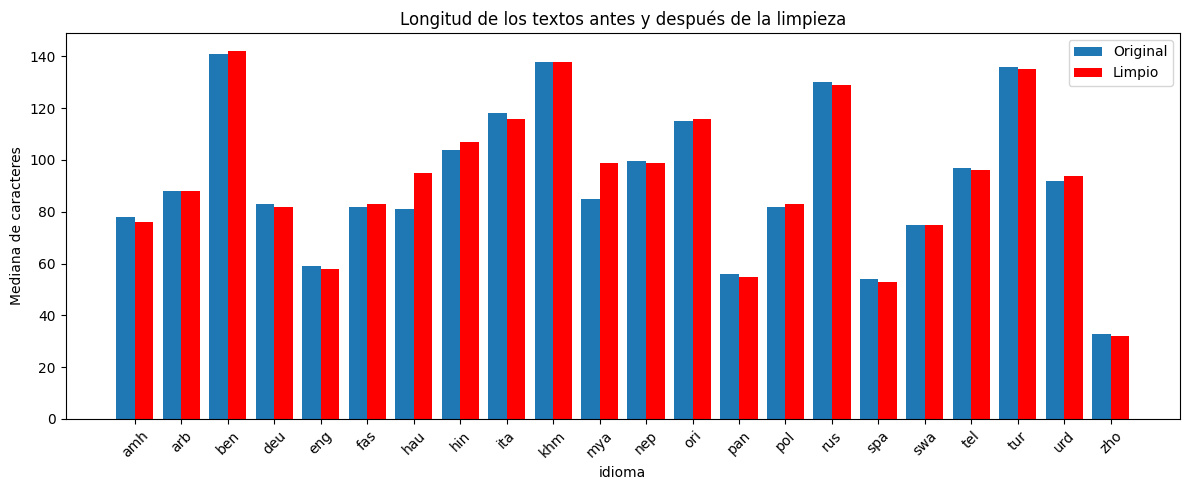

In [20]:
# Mediana de longitud antes y después de la limpieza
mediana_antes = datos.groupby('idioma')['text'].apply(lambda s: s.str.len().median())
mediana_despues = datos.groupby('idioma')['texto'].apply(lambda s: s.str.len().median())
x = np.arange(len(idiomas))

plt.figure(figsize = (12, 5))
plt.bar(x - 0.2, mediana_antes, width = 0.4, label = 'Original')
plt.bar(x + 0.2, mediana_despues, width = 0.4, color = 'red', label = 'Limpio')
plt.xticks(x, idiomas, rotation = 45)
plt.xlabel('idioma')
plt.ylabel('Mediana de caracteres')
plt.title('Longitud de los textos antes y después de la limpieza')
plt.legend()
plt.tight_layout()
plt.show()

La longitud mediana casi no cambia en la mayoría de los idiomas. Las excepciones son el birmano (`mya`) y el hausa (`hau`), donde los textos crecen debido a que usan muchos emojis y cada uno, que ocupaba un solo carácter, se convierte en un nombre como `face_with_tears_of_joy`.

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Duplicados después de la limpieza</span></div>

In [21]:
es_train = datos['particion'] == 'train'

# 1. Textos de train que, ya limpios, también están en test
fuga = es_train & datos['texto'].isin(datos.loc[~es_train, 'texto'])
print(f'Textos de train presentes en test: {fuga.sum()}')
print(datos.loc[fuga, 'idioma'].value_counts().head(5))

# Ejemplos: el texto original difiere, pero el limpio es el mismo
ejemplos = (datos.loc[fuga, ['idioma', 'texto', 'text']]
            .merge(datos.loc[~es_train, ['texto', 'text']], on = 'texto', suffixes = ('_train', '_test')))
ejemplos = ejemplos[ejemplos['text_train'] != ejemplos['text_test']]
display(ejemplos[ejemplos['texto'].str.len() <= 120].sample(4, random_state = random_state)[['idioma', 'text_train', 'text_test']])

Textos de train presentes en test: 84
idioma
swa    46
ori    14
tur     6
hin     4
eng     3
Name: count, dtype: int64


,idioma,text_train,text_test
66,swa,wajaluo ni walewale tu Hawaii kitu mzurii,wajaluo ni walewale tu hawaii kitu mzurii
74,swa,sisi wajaluo hatuna ukabila ndio mana tulisema kibaki tosha kumbe asante ya punda ni mateke,Sisi wajaluo hatuna Ukabila ndio mana tulisema Kibaki Tosha kumbe asante ya punda ni mateke
0,amh,ትምህርት ቤት ሰርተንላቸው አስተምረናቸው . ሰው ከጠላት ነፃ ሲወጣ ነው የሚጨፍረው፣ እነዚህ ገድለው ሬሳ ላይ ይጨፍራሉ . ??,ትምህርት ቤት ሰርተንላቸው አስተምረናቸው . ሰው ከጠላት ነፃ ሲወጣ ነው የሚጨፍረው፣ እነዚህ ገድለው ሬሳ ላይ ይጨፍራሉ .
56,swa,wacha hii census ya wakikuyu na wakalenjin iishe tujue wako wangapi,Wacha hii census ya wakikuyu na wakalenjin iishe tujue wako wangapi


Con los textos ya limpios, dos registros que solo se distinguían por una mención, la puntuación o las mayúsculas quedan idénticos, así que la fuga entre particiones se revisa de nuevo sobre `texto`. Al comparar el texto limpio la fuga detectada se multiplica, ya que de 4 textos idénticos se pasa a 84, casi todos de suajili (`swa`) y oriya (`ori`). En los ejemplos se ve que las copias solo cambian en mayúsculas, una mención o la puntuación final, entonces en la práctica son el mismo registro.

Estos textos se eliminan de `train`, mientras que `test` no se modifica, puesto que es el conjunto oficial de evaluación.

In [22]:
# 2. Duplicados dentro de train (que no están en test)
repetido = es_train & ~fuga & datos.duplicated(subset = 'texto', keep = False)
contradice = datos[repetido].groupby('texto')[etiquetas].nunique(dropna = False).gt(1).any(axis = 1)

eliminar_contradiccion = repetido & datos['texto'].isin(contradice[contradice].index)
eliminar_copia = repetido & ~eliminar_contradiccion & datos.duplicated(subset = 'texto', keep = 'first')

print(f'Textos repetidos dentro de train: {datos.loc[repetido, "texto"].nunique()}')
print(f'  con etiquetas contradictorias: {contradice.sum()}')
print(f"Duplicados que quedan en test (no se modifican): {datos.loc[~es_train, 'texto'].duplicated().sum()}")

eliminar = fuga | eliminar_contradiccion | eliminar_copia
display(pd.DataFrame({'registros eliminados': [fuga.sum(), eliminar_contradiccion.sum(), eliminar_copia.sum(), eliminar.sum()]},
                     index = ['presentes en test', 'etiquetas contradictorias', 'copias repetidas', 'total']))

datos = datos[~eliminar].reset_index(drop = True)
print(f"Tamaño final de train: {(datos['particion'] == 'train').sum()}")
print(f"Tamaño final de test: {(datos['particion'] == 'test').sum()}")

Textos repetidos dentro de train: 85
  con etiquetas contradictorias: 58
Duplicados que quedan en test (no se modifican): 21


,registros eliminados
presentes en test,84
etiquetas contradictorias,116
copias repetidas,27
total,227


Tamaño final de train: 73454
Tamaño final de test: 33288


Dentro de `train` se aplica otra regla. Si un texto repetido tiene las mismas etiquetas en todas sus copias, se conserva una sola, y si las etiquetas se contradicen, no hay forma de saber cuál es la correcta y se eliminan todas las copias.

Hay 85 textos repetidos y en 58 de ellos las copias no tienen las mismas etiquetas (en 14 cambia la propia polarización y en el resto cambian los tipos o las manifestaciones). Esto confirma que la anotación tiene ruido, sobre todo en las subtareas 2 y 3, como ya sugerían los 4 casos iniciales. En total se eliminan 227 registros de `train` (0.3%), una pérdida mínima a cambio de una evaluación limpia. Los 21 duplicados que quedan dentro de `test` se dejan como están.

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Representación TF-IDF</span></div>

In [23]:
parametros = dict(analyzer = 'char_wb', ngram_range = (2, 5), sublinear_tf = True,
                  min_df = 2, lowercase = False, dtype = np.float32)

# Ejemplo de los n-gramas que genera una palabra
print(TfidfVectorizer(**parametros).build_analyzer()('odio.'))

[' o', 'od', 'di', 'io', 'o.', '. ', ' od', 'odi', 'dio', 'io.', 'o. ', ' odi', 'odio', 'dio.', 'io. ', ' odio', 'odio.', 'dio. ']


Cada texto se representa con TF-IDF sobre n-gramas de caracteres. La celda define los parámetros del vectorizador y muestra, como ejemplo, los n-gramas que genera la palabra `odio.`. Los parámetros elegidos son los siguientes.

* `analyzer = 'char_wb'` genera n-gramas de caracteres que no cruzan de una palabra a otra. Cada palabra se rellena con un espacio a cada lado, así que también se marca el inicio y el final de palabra, como se ve en `' odio'`. En chino, jemer y birmano, donde no hay espacios, cada frase se trata como una sola palabra.
* `ngram_range = (2, 5)` va desde bigramas, que capturan afijos cortos, hasta pentagramas, que ya cubren raíces completas.
* `sublinear_tf = True` usa $1 + \log(tf)$ en lugar de la frecuencia cruda, para que un n-grama repetido muchas veces en un texto no domine.
* `min_df = 2` descarta los n-gramas que aparecen en un solo texto, puesto que no generalizan.
* `lowercase = False` evita una conversión innecesaria, ya que los textos ya están en minúsculas.

El vectorizador se ajusta solo con `train` y después transforma `test`, de modo que ni el vocabulario ni los pesos IDF usan información de prueba. Se construyen dos versiones, un vectorizador global con todos los idiomas y un vectorizador para cada idioma.

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Vectorizador global</span></div>

In [24]:
es_train = datos['particion'] == 'train'

vectorizador_global = TfidfVectorizer(**parametros)
X_train_global = vectorizador_global.fit_transform(datos.loc[es_train, 'texto'])
X_test_global = vectorizador_global.transform(datos.loc[~es_train, 'texto'])

print(f'Dimensión de train: {X_train_global.shape}')
print(f'Dimensión de test: {X_test_global.shape}')
print(f'n-gramas distintos de cero por texto (mediana): {int(np.median(np.diff(X_train_global.indptr)))}')
print(f'Densidad de la matriz de train: {X_train_global.nnz / np.prod(X_train_global.shape):.6f}')

Dimensión de train: (73454, 762279)
Dimensión de test: (33288, 762279)
n-gramas distintos de cero por texto (mediana): 230
Densidad de la matriz de train: 0.000351


El vectorizador global produce matrices de 762,279 columnas. Cada texto activa una mediana de 230 n-gramas, por lo que la matriz es muy dispersa (solo el 0.035% de sus entradas es distinto de cero) y se mantiene en formato disperso.

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Vectorizadores por idioma</span></div>

In [25]:
vectorizadores = {}
X_train_idioma = {}
X_test_idioma = {}

for idioma in idiomas:
    en_idioma = datos['idioma'] == idioma
    vectorizadores[idioma] = TfidfVectorizer(**parametros)
    X_train_idioma[idioma] = vectorizadores[idioma].fit_transform(datos.loc[es_train & en_idioma, 'texto'])
    X_test_idioma[idioma] = vectorizadores[idioma].transform(datos.loc[~es_train & en_idioma, 'texto'])

dimensiones = pd.DataFrame({'n_train': {i: X_train_idioma[i].shape[0] for i in idiomas},
                            'n_test': {i: X_test_idioma[i].shape[0] for i in idiomas},
                            'n_gramas': {i: X_train_idioma[i].shape[1] for i in idiomas}})
print(f"Suma de vocabularios por idioma: {dimensiones['n_gramas'].sum()}")
print(f'Vocabulario global: {X_train_global.shape[1]}')

Suma de vocabularios por idioma: 922435
Vocabulario global: 762279


Se ajusta un vectorizador independiente para cada idioma, cada uno con su propio vocabulario y sus propios pesos IDF. La suma de los 22 vocabularios (≈922 mil n-gramas) resulta mayor que el vocabulario global (≈762 mil).

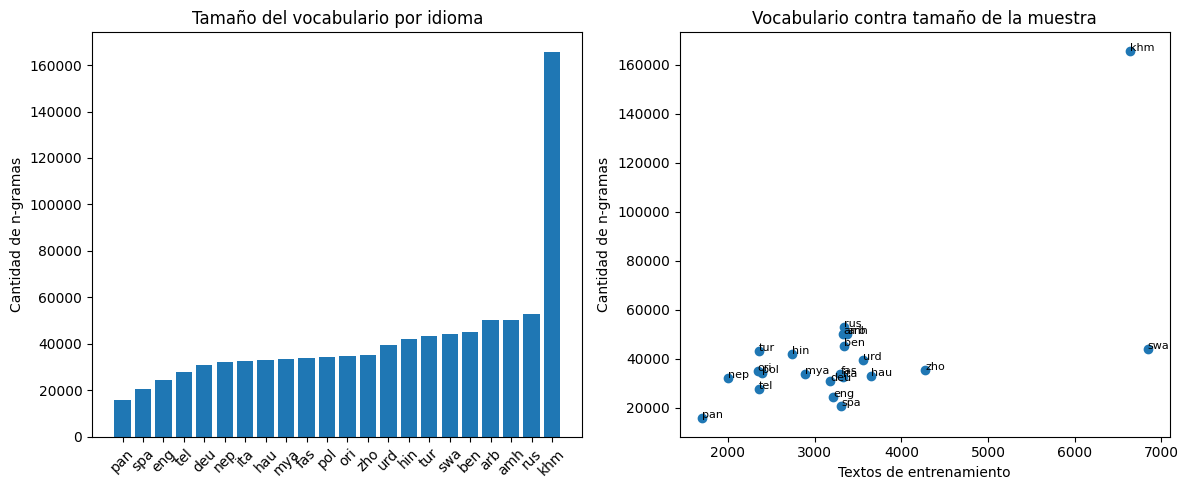

In [36]:
# Tamaño del vocabulario por idioma
orden = dimensiones.sort_values('n_gramas')

plt.figure(figsize = (12, 5))

plt.subplot(1, 2, 1)
plt.bar(orden.index, orden['n_gramas'])
plt.xticks(rotation = 45)
plt.ylabel('Cantidad de n-gramas')
plt.title('Tamaño del vocabulario por idioma')

plt.subplot(1, 2, 2)
plt.scatter(dimensiones['n_train'], dimensiones['n_gramas'])
for idioma in idiomas:
    plt.annotate(idioma, (dimensiones.loc[idioma, 'n_train'], dimensiones.loc[idioma, 'n_gramas']), fontsize = 8)
plt.xlabel('Textos de entrenamiento')
plt.ylabel('Cantidad de n-gramas')
plt.title('Vocabulario contra tamaño de la muestra')

plt.tight_layout()
plt.show()

El vocabulario global es menor que la suma de los vocabularios por idioma debido a que los idiomas que comparten escritura también comparten muchos n-gramas, que en el global se cuentan una sola vez. El inglés, el español, el alemán, el italiano, el polaco, el hausa, el suajili y el turco usan el alfabeto latino, mientras que el árabe, el persa, el urdu y el panyabí usan el alfabeto árabe. En este conjunto el panyabí está escrito por completo en shahmukhi, la variante del alfabeto árabe que se usa en Pakistán, y no en gurmukhi, y por eso comparte tantos n-gramas con el urdu.

Las gráficas muestran que el tamaño del vocabulario depende más de la escritura que de la cantidad de textos. El suajili tiene el doble de textos que la mayoría y un vocabulario promedio, mientras que el jemer (`khm`) llega a casi 166 mil n-gramas. Esto pasa porque el jemer no separa palabras con espacios, entonces `char_wb` trata frases completas como una sola palabra y casi cada combinación de cinco caracteres es distinta. En la etapa de modelado hay que tener en cuenta que el jemer tendrá muchas más variables que textos.

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">n-gramas asociados a la polarización</span></div>

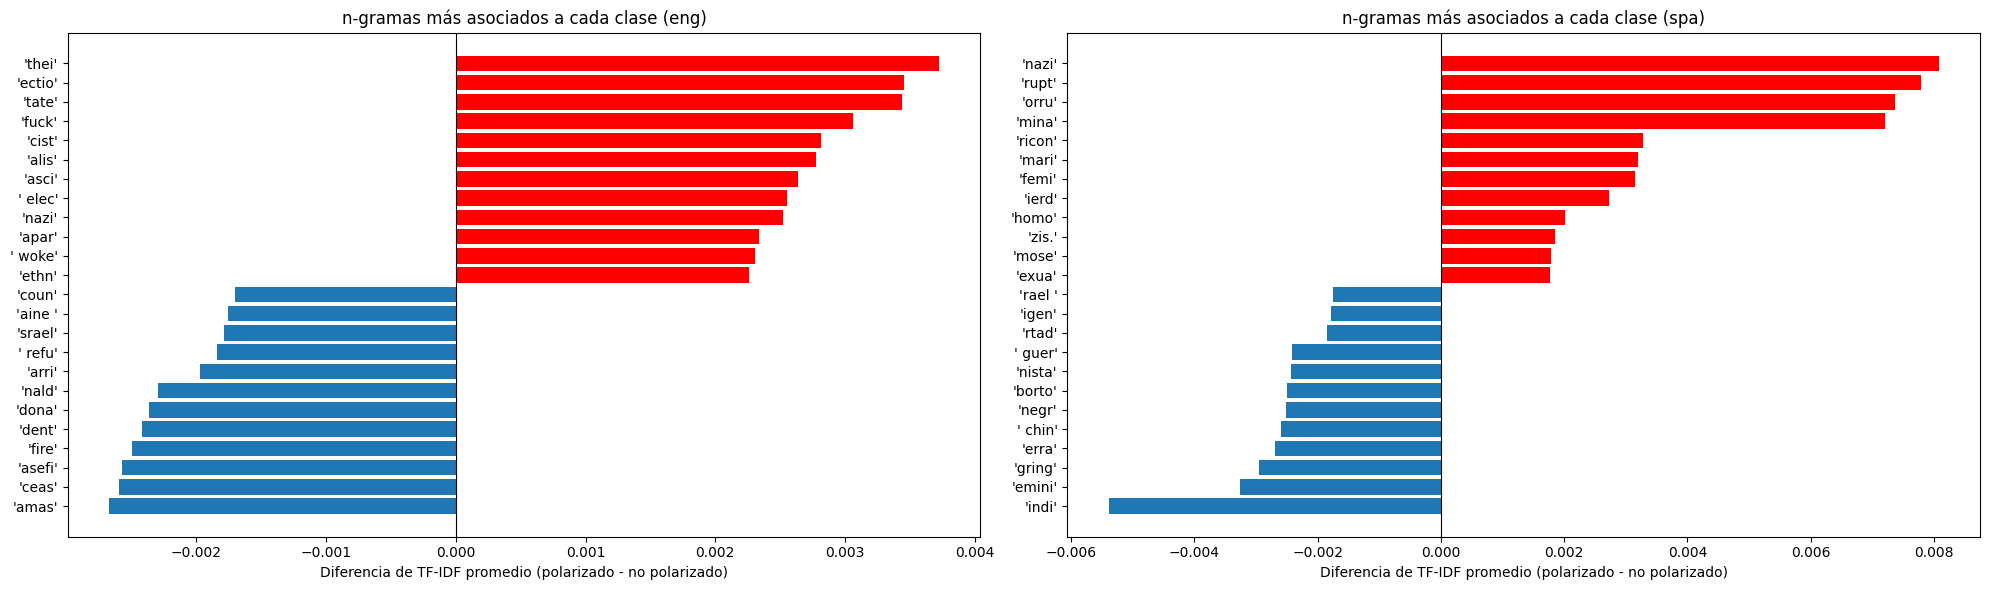

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(20, 6))

for idioma, ax in zip(['eng', 'spa'], axes):
    en_idioma = datos['idioma'] == idioma
    y = datos.loc[es_train & en_idioma, 'polarization'].values
    X = X_train_idioma[idioma]
    diferencia = pd.Series(
        np.asarray(X[y == 1].mean(axis=0) - X[y == 0].mean(axis=0)).ravel(),
        index=vectorizadores[idioma].get_feature_names_out()
    )
    diferencia = diferencia[diferencia.index.str.strip().str.len() >= 4]

    # Se descartan los n-gramas que comparten un trigrama con otro de mayor diferencia
    seleccion = {}
    for signo, candidatos in [(-1, diferencia.sort_values()), (1, diferencia.sort_values(ascending=False))]:
        elegidos = []
        for ngrama in candidatos.index:
            trigramas = {ngrama.strip()[k:k + 3] for k in range(len(ngrama.strip()) - 2)}
            if all(trigramas.isdisjoint(t) for _, t in elegidos):
                elegidos.append((ngrama, trigramas))
            if len(elegidos) == 12:
                break
        seleccion[signo] = [n for n, _ in elegidos]
    extremos = pd.concat([diferencia[seleccion[-1]], diferencia[seleccion[1]].iloc[::-1]])

    ax.barh(
        [repr(n) for n in extremos.index],
        extremos.values,
        color=['tab:blue' if v < 0 else 'red' for v in extremos.values]
    )
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_xlabel('Diferencia de TF-IDF promedio (polarizado - no polarizado)')
    ax.set_title(f'n-gramas más asociados a cada clase ({idioma})')

plt.tight_layout()
plt.show()

Para comprobar que la representación captura información útil, se compara el peso TF-IDF promedio de cada n-grama entre textos polarizados y no polarizados, en inglés y en español. Para que sean legibles solo se muestran n-gramas de al menos cuatro caracteres. Además, como una misma palabra genera muchos n-gramas traslapados (`' stat'`, `'stat'`, `'state'`, `'tate'`), de cada grupo se conserva solo el de mayor diferencia.

Los n-gramas que aparecen tienen sentido. En inglés, del lado polarizado están *racist/fascist*, *nazi*, *woke*, *apartheid* y *election*, y del lado no polarizado *hamas*, *ceasefire*, *israel*, *refugee* y *donald*, que corresponden a titulares de noticias. En español, del lado polarizado están *nazi/feminazis*, *corrupto*, *maricón*, *homo* y *mierda*, y del lado no polarizado *india*, *feminismo*, *gringo*, *chino*, *aborto* y *guerra*.

Los temas sensibles (Israel, aborto, feminismo) quedan del lado no polarizado, mientras que el lado polarizado lo marcan los insultos y las etiquetas despectivas (*feminazi* frente a *feminismo*). Esto sugiere que la polarización depende más de cómo se habla de un tema que del tema mismo, y eso es algo que los n-gramas sí pueden captar.

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Guardado</span></div>

In [28]:
os.makedirs(ruta_procesado, exist_ok = True)
os.makedirs(os.path.join(ruta_tfidf, 'idioma'), exist_ok = True)

# Textos limpios con etiquetas
columnas = ['id', 'idioma', 'texto'] + etiquetas
datos.loc[es_train, columnas].to_csv(os.path.join(ruta_procesado, 'train.csv'), index = False)
datos.loc[~es_train, columnas].assign(canary = canary).to_csv(os.path.join(ruta_procesado, 'test.csv'), index = False)

# Vectorizadores y matrices
joblib.dump(vectorizador_global, os.path.join(ruta_tfidf, 'vectorizador_global.joblib'))
sparse.save_npz(os.path.join(ruta_tfidf, 'X_train_global.npz'), X_train_global)
sparse.save_npz(os.path.join(ruta_tfidf, 'X_test_global.npz'), X_test_global)

joblib.dump(vectorizadores, os.path.join(ruta_tfidf, 'vectorizadores_idioma.joblib'))
for idioma in idiomas:
    sparse.save_npz(os.path.join(ruta_tfidf, 'idioma', f'X_train_{idioma}.npz'), X_train_idioma[idioma])
    sparse.save_npz(os.path.join(ruta_tfidf, 'idioma', f'X_test_{idioma}.npz'), X_test_idioma[idioma])

for carpeta in [ruta_procesado, ruta_tfidf]:
    tamano = sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(carpeta) for f in fs)
    print(f'{carpeta}: {tamano / 1e6:.1f} MB')

data\procesado: 31.1 MB
data\tfidf: 293.8 MB


Se guardan dos tipos de archivos.

* En `data/procesado/` quedan los textos limpios con sus etiquetas (`train.csv` y `test.csv`), en el mismo orden que las filas de las matrices. El archivo de prueba conserva la columna `canary` del original, ya que es la cadena que permite detectar si el conjunto de prueba terminó en los datos de entrenamiento de algún modelo de lenguaje, y quitarla al publicar una copia derivada anularía ese propósito.
* En `data/tfidf/` quedan los vectorizadores ajustados (`joblib`) y las matrices dispersas (`.npz`). La matriz global sigue el orden de los CSV y las de cada idioma siguen el orden de las filas de ese idioma en los CSV. Esta carpeta pesa cientos de MB y se puede regenerar con este notebook, por lo que está excluida del repositorio en `.gitignore`.

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Conclusiones</span></div>

La fuga entre particiones se revisó sobre el texto limpio. Se encontraron 84 textos de `train` que también estaban en `test` (antes de limpiar solo 4 eran idénticos) y se eliminaron. Dentro de `train` se conservó una sola copia de los textos repetidos con etiquetas iguales y se eliminaron los 58 con etiquetas contradictorias. En total salieron 227 registros, y `train` quedó con 73,454.

La limpieza es la misma para los 22 idiomas y se apoya en propiedades Unicode en lugar de reglas particulares de cada idioma. Incluye normalización NFKC, marcadores unificados (`xxuser`, `xxurl`), caracteres repetidos reducidos a dos, emojis convertidos en tokens, hashtags sin `#`, signos de fin de oración de cualquier escritura convertidos en punto, minúsculas (con la regla especial del turco) y espacios colapsados. Usar `regex` con categorías Unicode en lugar de `re` fue indispensable, puesto que con `\w` se habrían destruido las palabras en hindi, bengalí, telugu, oriya, nepalí, jemer y birmano.

La representación TF-IDF de n-gramas de caracteres (de 2 a 5, con `char_wb`) produce un vocabulario global de ≈762 mil n-gramas y 22 vocabularios por idioma, que van de 16 mil (`pan`) a 166 mil (`khm`) n-gramas. Ambas versiones quedaron guardadas en `data/tfidf/` para compararlas en la etapa de modelado.

Una primera comparación entre clases muestra que los n-gramas capturan señal útil, ya que los insultos, las etiquetas despectivas y los pronombres de grupo se asocian a la polarización, mientras que el vocabulario de noticias se asocia a los textos no polarizados.